<a href="https://colab.research.google.com/github/Nboev2004/InClassAssignments/blob/main/HW6_Meridian_Food_Group.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Original dataset:
Rows and columns: (2830, 13)
Column names: ['restaurant_id', 'brand', 'market', 'product_hierarchy', 'net_sales_2023', 'units_2023', 'category_orders_2023', 'net_sales_2024', 'units_2024', 'category_orders_2024', 'net_sales_2025', 'units_2025', 'category_orders_2025']
Missing values:
restaurant_id           0
brand                   0
market                  0
product_hierarchy       0
net_sales_2023          0
units_2023              0
category_orders_2023    0
net_sales_2024          0
units_2024              0
category_orders_2024    0
net_sales_2025          0
units_2025              0
category_orders_2025    0
dtype: int64


,restaurant_id,brand,market,product_hierarchy,net_sales_2023,units_2023,category_orders_2023,net_sales_2024,units_2024,category_orders_2024,net_sales_2025,units_2025,category_orders_2025
0,CC-0011,Copper Cup,Nashville,Beverages | Coffee,29.23,7,7,81.80,20,19,190.76,44,42
1,CC-0011,Copper Cup,Nashville,Beverages | Seasonal Beverage,5.79,1,1,23.16,4,4,69.48,12,12
2,CC-0011,Copper Cup,Nashville,Beverages | Tea,13.96,4,4,10.47,3,3,6.98,2,2
3,CC-0011,Copper Cup,Nashville,Food | Food,49.72,8,7,116.18,22,19,239.57,43,37
4,CC-0012,Copper Cup,Atlanta,Beverages | Coffee,48.48,12,11,64.95,15,14,181.68,42,39
5,CC-0012,Copper Cup,Atlanta,Beverages | Seasonal Beverage,23.16,4,4,17.37,3,3,40.53,7,6
6,CC-0012,Copper Cup,Atlanta,Beverages | Tea,3.49,1,1,10.47,3,3,34.90,10,10
7,CC-0012,Copper Cup,Atlanta,Food | Food,77.57,13,12,67.38,12,12,217.39,41,34
8,CC-0013,Copper Cup,Atlanta,Beverages | Coffee,45.10,10,9,70.43,17,17,140.18,32,31
9,CC-0013,Copper Cup,Atlanta,Beverages | Seasonal Beverage,17.37,3,3,34.74,6,6,57.90,10,9



CLEANED DATASET:
Shape: (8490, 9)
Columns: ['restaurant_id', 'brand', 'market', 'department', 'category', 'year', 'category_orders', 'net_sales', 'units']


,restaurant_id,brand,market,department,category,year,category_orders,net_sales,units
0,CC-0011,Copper Cup,Nashville,Beverages,Coffee,2023,7.0,29.23,7.0
1,CC-0011,Copper Cup,Nashville,Beverages,Coffee,2024,19.0,81.80,20.0
2,CC-0011,Copper Cup,Nashville,Beverages,Coffee,2025,42.0,190.76,44.0
3,CC-0011,Copper Cup,Nashville,Beverages,Seasonal Beverage,2023,1.0,5.79,1.0
4,CC-0011,Copper Cup,Nashville,Beverages,Seasonal Beverage,2024,4.0,23.16,4.0
5,CC-0011,Copper Cup,Nashville,Beverages,Seasonal Beverage,2025,12.0,69.48,12.0
6,CC-0011,Copper Cup,Nashville,Beverages,Tea,2023,4.0,13.96,4.0
7,CC-0011,Copper Cup,Nashville,Beverages,Tea,2024,3.0,10.47,3.0
8,CC-0011,Copper Cup,Nashville,Beverages,Tea,2025,2.0,6.98,2.0
9,CC-0011,Copper Cup,Nashville,Food,Food,2023,7.0,49.72,8.0


Cleaned dataset saved successfully.


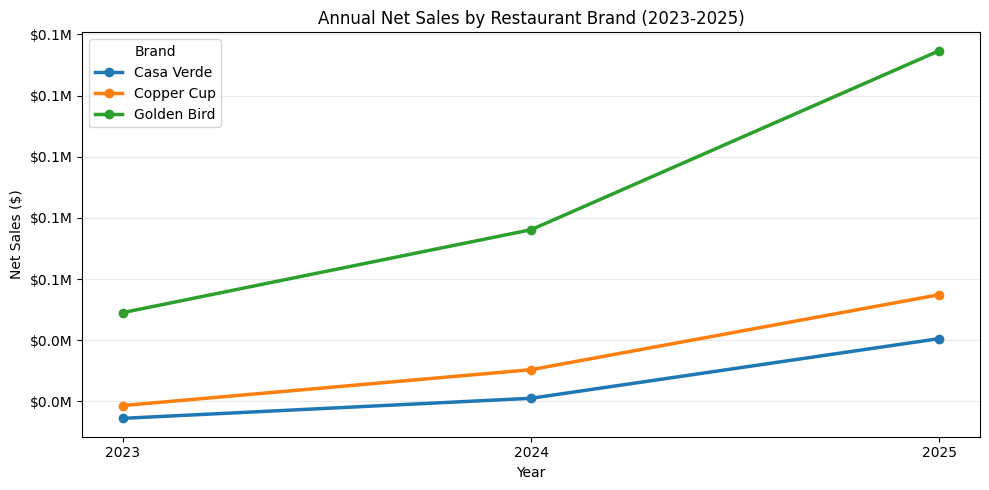


QUESTION 1 INTERPRETATION:
Casa Verde: Annual net sales increased from $14,418 in 2023 to $40,498 in 2025.
Copper Cup: Annual net sales increased from $18,605 in 2023 to $54,868 in 2025.
Golden Bird: Annual net sales increased from $49,018 in 2023 to $134,684 in 2025.


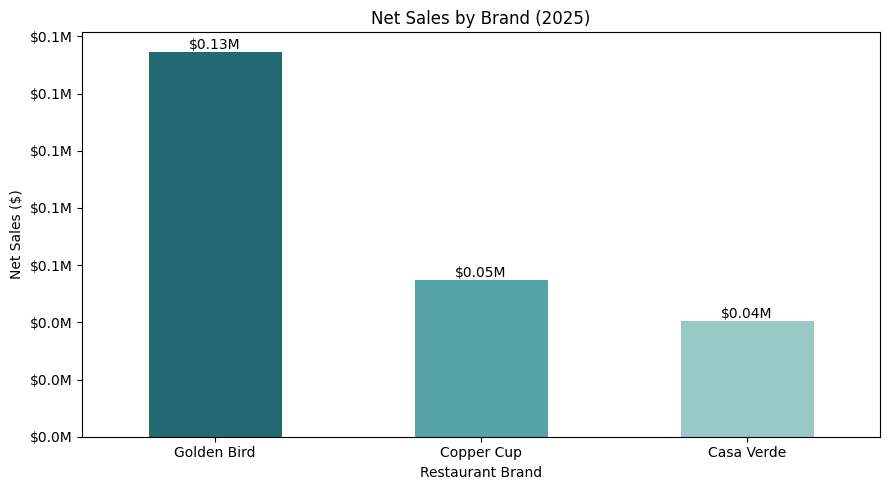


QUESTION 2 INTERPRETATION:
Golden Bird generated the most net sales in 2025, totaling $134,684.


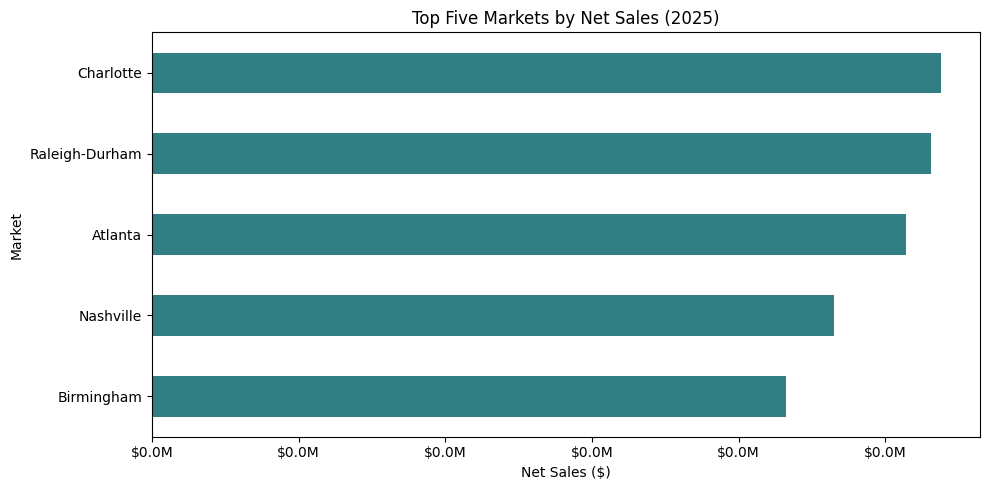


QUESTION 3 INTERPRETATION:
The top five markets in 2025 were Charlotte, Raleigh-Durham, Atlanta, Nashville, Birmingham, with Charlotte leading at $26,887 in net sales.


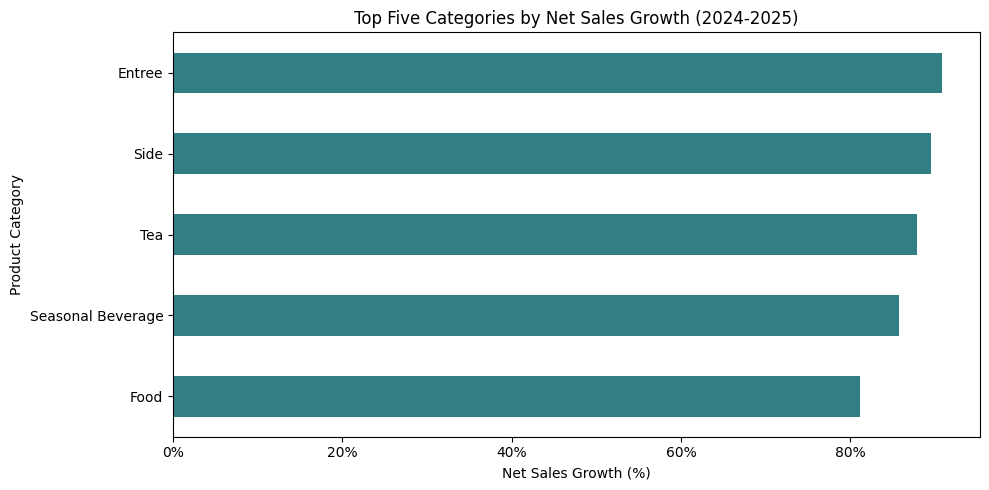


QUESTION 4 INTERPRETATION:
The five categories with the largest percentage increases were Entree (90.8%), Side (89.6%), Tea (87.9%), Seasonal Beverage (85.8%), Food (81.1%). Categories with zero sales in 2024 were excluded.

HOMEWORK 6 ANALYSIS FINISHED.


In [1]:

# HOMEWORK 6 - MERIDIAN FOOD GROUP
# Name: Nick Boev

# IMPORT PACKAGES
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# READ IN AND INSPECT DATA
url = "https://dxl-datasets.s3.us-east-1.amazonaws.com/data/meridian/annual_category_report.csv"
report = pd.read_csv(url)

print("Original dataset:")
print("Rows and columns:", report.shape)
print("Column names:", report.columns.tolist())
print("Missing values:")
print(report.isna().sum())
display(report.head(10))


# RESTRUCTURE DATA
# Step 1: Split department and category using .str.split()
analytics_ready = report.copy()

hierarchy_candidates = [
    c for c in analytics_ready.columns
    if "hierarchy" in c.lower()
    or "department_category" in c.lower()
]

if hierarchy_candidates:
    hierarchy_col = hierarchy_candidates[0]
else:
    hierarchy_candidates = [
        c for c in analytics_ready.select_dtypes(include="object").columns
        if analytics_ready[c].astype(str).str.contains(
            " | ", regex=False
        ).any()
    ]
    if not hierarchy_candidates:
        raise ValueError("Could not find department/category column.")
    hierarchy_col = hierarchy_candidates[0]

analytics_ready[["department", "category"]] = (
    analytics_ready[hierarchy_col]
    .astype(str)
    .str.split(" | ", n=1, expand=True, regex=False)
)

analytics_ready["department"] = analytics_ready["department"].str.strip()
analytics_ready["category"] = analytics_ready["category"].str.strip()
analytics_ready = analytics_ready.drop(columns=hierarchy_col)

# Step 2: Use melt() to convert year columns into rows
metric_names = ("net_sales", "units", "category_orders")

measure_columns = [
    c for c in analytics_ready.columns
    if any(
        c.startswith(metric + "_") and c.rsplit("_", 1)[-1].isdigit()
        for metric in metric_names
    )
]

if not measure_columns:
    raise ValueError("Could not find metric-year columns.")

id_columns = [
    c for c in analytics_ready.columns
    if c not in measure_columns
]

analytics_ready = analytics_ready.melt(
    id_vars=id_columns,
    value_vars=measure_columns,
    var_name="metric_year",
    value_name="value"
)

# Step 3: Separate metric name and year
analytics_ready[["metric", "year"]] = (
    analytics_ready["metric_year"].str.rsplit(
        "_", n=1, expand=True
    )
)

analytics_ready = analytics_ready.drop(columns="metric_year")
analytics_ready["year"] = pd.to_numeric(analytics_ready["year"])
analytics_ready["value"] = pd.to_numeric(
    analytics_ready["value"], errors="coerce"
)

# Step 4: Use pivot() to create separate metric columns
index_columns = [
    c for c in analytics_ready.columns
    if c not in ["metric", "value"]
]

analytics_ready = analytics_ready.pivot(
    index=index_columns,
    columns="metric",
    values="value"
).reset_index()

analytics_ready.columns.name = None

print("\nCLEANED DATASET:")
print("Shape:", analytics_ready.shape)
print("Columns:", analytics_ready.columns.tolist())
display(analytics_ready.head(10))

assert set(metric_names).issubset(analytics_ready.columns)


# SAVE CLEANED DATASET
analytics_ready.to_csv(
    "meridian_analytics_ready.csv", index=False
)
print("Cleaned dataset saved successfully.")


# QUESTION 1 - SALES TRENDS BY BRAND
sales_by_brand_year = (
    analytics_ready[
        analytics_ready["year"].between(2023, 2025)
    ]
    .groupby(["year", "brand"], as_index=False)["net_sales"]
    .sum()
)

trend = sales_by_brand_year.pivot(
    index="year",
    columns="brand",
    values="net_sales"
)

ax = trend.plot(
    marker="o",
    linewidth=2.5,
    figsize=(10, 5)
)

ax.set(
    title="Annual Net Sales by Restaurant Brand (2023-2025)",
    xlabel="Year",
    ylabel="Net Sales ($)"
)
ax.set_xticks([2023, 2024, 2025])
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"${x/1e6:,.1f}M")
)
ax.legend(title="Brand")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print("\nQUESTION 1 INTERPRETATION:")
for brand in trend.columns:
    start = trend.loc[2023, brand]
    end = trend.loc[2025, brand]
    direction = (
        "increased" if end > start
        else "decreased" if end < start
        else "remained unchanged"
    )
    print(
        f"{brand}: Annual net sales {direction} "
        f"from ${start:,.0f} in 2023 "
        f"to ${end:,.0f} in 2025."
    )


# QUESTION 2 - RESTAURANT BRAND COMPARISON
brand_2025 = (
    analytics_ready.loc[analytics_ready["year"] == 2025]
    .groupby("brand")["net_sales"]
    .sum()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(9, 5))

brand_2025.plot(
    kind="bar",
    ax=ax,
    color=["#246a73", "#55a3a5", "#99c9c7"]
)

ax.set(
    title="Net Sales by Brand (2025)",
    xlabel="Restaurant Brand",
    ylabel="Net Sales ($)"
)
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"${x/1e6:,.1f}M")
)
ax.tick_params(axis="x", rotation=0)

for i, value in enumerate(brand_2025):
    ax.text(
        i, value,
        f"${value/1e6:,.2f}M",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

print("\nQUESTION 2 INTERPRETATION:")
print(
    f"{brand_2025.index[0]} generated the most "
    f"net sales in 2025, totaling "
    f"${brand_2025.iloc[0]:,.0f}."
)


# QUESTION 3 - TOP FIVE MARKETS
market_2025 = (
    analytics_ready.loc[analytics_ready["year"] == 2025]
    .groupby("market")["net_sales"]
    .sum()
    .nlargest(5)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 5))

market_2025.plot(
    kind="barh",
    ax=ax,
    color="#327e85"
)

ax.set(
    title="Top Five Markets by Net Sales (2025)",
    xlabel="Net Sales ($)",
    ylabel="Market"
)
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"${x/1e6:,.1f}M")
)

plt.tight_layout()
plt.show()

market_ranked = market_2025.sort_values(ascending=False)

print("\nQUESTION 3 INTERPRETATION:")
print(
    "The top five markets in 2025 were "
    + ", ".join(market_ranked.index.astype(str))
    + f", with {market_ranked.index[0]} leading "
    + f"at ${market_ranked.iloc[0]:,.0f} in net sales."
)


# QUESTION 4 - CATEGORY GROWTH
category_sales = (
    analytics_ready[
        analytics_ready["year"].isin([2024, 2025])
    ]
    .groupby(["category", "year"])["net_sales"]
    .sum()
    .unstack("year", fill_value=0)
)

# Exclude categories with zero sales in 2024
category_sales = category_sales.loc[
    category_sales[2024] > 0
].copy()

category_sales["growth_pct"] = (
    (category_sales[2025] - category_sales[2024])
    / category_sales[2024]
    * 100
)

top_growth = (
    category_sales["growth_pct"]
    .nlargest(5)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 5))

top_growth.plot(
    kind="barh",
    ax=ax,
    color="#327e85"
)

ax.set(
    title="Top Five Categories by Net Sales Growth (2024-2025)",
    xlabel="Net Sales Growth (%)",
    ylabel="Product Category"
)
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:.0f}%")
)

plt.tight_layout()
plt.show()

ranked = top_growth.sort_values(ascending=False)

print("\nQUESTION 4 INTERPRETATION:")
print(
    "The five categories with the largest "
    "percentage increases were "
    + ", ".join(
        f"{category} ({growth:.1f}%)"
        for category, growth in ranked.items()
    )
    + ". Categories with zero sales in 2024 were excluded."
)

print("\nHOMEWORK 6 ANALYSIS FINISHED.")
